# Tech Challenge Fase 4 — Monitoramento multimodal de pacientes

Demonstração passo a passo do fluxo: **vídeo** (YOLOv8-pose / OpenPose e YOLOv8), **áudio** (Azure Speech to Text, Azure Text Analytics e biomarcadores vocais), **detecção de anomalias** (sinais vitais, prescrições e movimentação), **fusão multimodal** e **alertas para a equipe médica**.

> Projeto acadêmico, com dados sintéticos ou públicos. Não deve ser utilizado para decisões clínicas.

## 1. Preparação do ambiente
No Google Colab, a célula abaixo clona o repositório e instala as dependências.

In [1]:
import os, sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !git clone -q https://github.com/julianajjo/pos-tech-challenge-fase-4.git
    %cd pos-tech-challenge-fase-4
    !pip -q install -r requirements.txt
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, "src")

### Chaves do Azure (opcional)
Cadastre `AZURE_SPEECH_KEY`, `AZURE_SPEECH_REGION`, `AZURE_LANGUAGE_KEY` e `AZURE_LANGUAGE_ENDPOINT` nos *Secrets* do Colab ou no arquivo `.env`. Sem as chaves, o sistema usa as alternativas locais.

In [2]:
if IN_COLAB:
    from google.colab import userdata
    for k in ["AZURE_SPEECH_KEY", "AZURE_SPEECH_REGION", "AZURE_LANGUAGE_KEY", "AZURE_LANGUAGE_ENDPOINT"]:
        try:
            os.environ[k] = userdata.get(k)
        except Exception:
            pass

import warnings, logging
warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.WARNING)
import pandas as pd
from IPython.display import Image, display, Markdown
from hospital_monitor.config import load_config, PROJECT_ROOT
from hospital_monitor.pipeline import prepare_samples

cfg = load_config()
files = prepare_samples(PROJECT_ROOT / "data" / "samples")
print("Azure Speech configurado:", bool(cfg["azure"]["speech_key"]))
print("Azure Language configurado:", bool(cfg["azure"]["language_key"]))

Azure Speech configurado: False
Azure Language configurado: False


## 2. Sinais vitais
Quatro pacientes, 48 h com uma amostra por minuto. Episódios clínicos conhecidos foram inseridos para avaliar a detecção:
- **P001**: deterioração progressiva compatível com sepse a partir de 11/11 06:00;
- **P002**: dessaturação aguda em 10/11 20:00;
- **P003**: paciente estável (controle);
- **P004**: crise hipertensiva em 11/11 12:00.

In [3]:
from hospital_monitor.anomaly.vitals import VitalSignsAnomalyDetector
from hospital_monitor.pipeline import evaluate_vitals

vitals = pd.read_csv(files["vitals"], parse_dates=["timestamp"])
display(vitals.head())
det = VitalSignsAnomalyDetector(cfg["vitals"])
scored, episodes = det.detect(vitals)
pd.DataFrame([{"paciente": e.patient_id, "início": e.start, "fim": e.end, "NEWS2 máx": e.max_news2,
               "sinais": ", ".join(e.signals), "métodos": ", ".join(e.methods), "severidade": e.severity.name}
              for e in episodes])

,timestamp,patient_id,hr,sbp,dbp,spo2,rr,temp
0,2026-11-10 00:00:00,P001,74.0,118.0,73.0,97.5,15.0,36.6
1,2026-11-10 00:01:00,P001,75.0,116.0,71.0,96.9,14.0,36.6
2,2026-11-10 00:02:00,P001,74.0,117.0,74.0,97.1,13.0,36.5
3,2026-11-10 00:03:00,P001,73.0,118.0,73.0,97.7,14.0,36.5
4,2026-11-10 00:04:00,P001,73.0,118.0,73.0,97.0,13.0,36.5


,paciente,início,fim,NEWS2 máx,sinais,métodos,severidade
0,P001,2026-11-11 07:14:00,2026-11-11 07:21:00,3,,Isolation Forest,BAIXA
1,P001,2026-11-11 07:30:00,2026-11-11 23:59:00,13,"hr, rr, sbp, spo2, temp","NEWS2, Isolation Forest",CRITICA
2,P002,2026-11-10 20:01:00,2026-11-10 20:23:00,7,"hr, rr, spo2","NEWS2, z-score robusto, Isolation Forest",CRITICA
3,P004,2026-11-11 12:02:00,2026-11-11 12:30:00,1,"dbp, hr, sbp","z-score robusto, Isolation Forest",MEDIA


In [4]:
ev = evaluate_vitals(episodes, pd.read_csv(files["episodes"]), scored)
print(f"Recall: {ev['recall']:.0%} | episódios falsos: {ev['falsos_positivos']} | artefatos removidos: {int(scored['artifact'].sum())}")
pd.DataFrame(ev["episodios"])

Recall: 100% | episódios falsos: 0 | artefatos removidos: 24


,paciente,episodio,inicio_real,detectado,primeira_deteccao,atraso_min,somente_news2_ge5,metodos
0,P001,deterioracao_sepse,2026-11-11 06:00:00,True,2026-11-11 07:14:00,74.0,2026-11-11 08:10:00,"[Isolation Forest, NEWS2]"
1,P002,dessaturacao,2026-11-10 20:00:00,True,2026-11-10 20:01:00,1.0,2026-11-10 20:02:00,"[Isolation Forest, NEWS2, z-score robusto]"
2,P004,crise_hipertensiva,2026-11-11 12:00:00,True,2026-11-11 12:02:00,2.0,não detectaria,"[Isolation Forest, z-score robusto]"


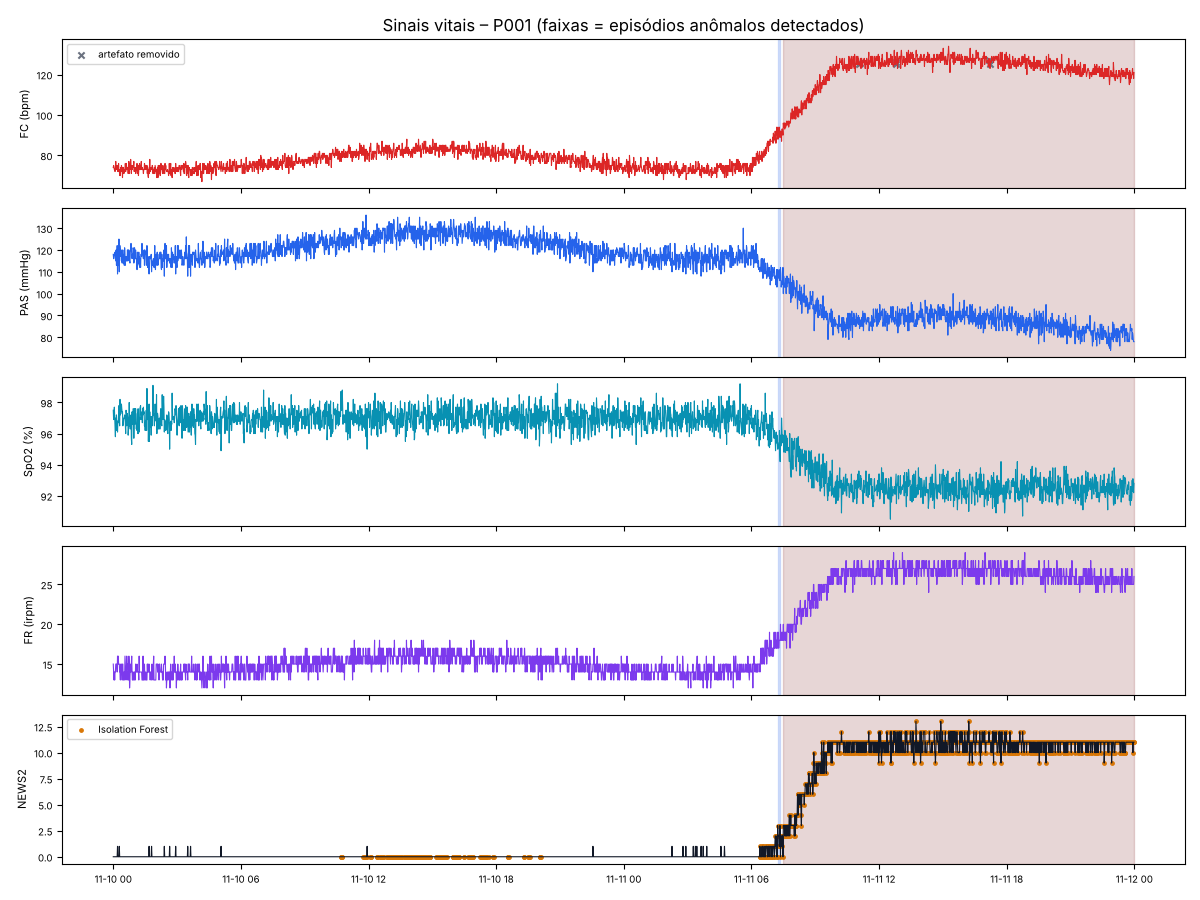

In [5]:
from hospital_monitor.report import plot_vitals
from pathlib import Path
Path("outputs/figuras").mkdir(parents=True, exist_ok=True)
display(Image(plot_vitals(scored, episodes, "P001", Path("outputs/figuras/vitais_P001.png"))))

### Monitoramento em tempo real
O `StreamingVitalsMonitor` recebe uma amostra por minuto e alerta no início do episódio e quando a gravidade aumenta.

In [6]:
from hospital_monitor.anomaly.vitals import StreamingVitalsMonitor
p2 = vitals[vitals.patient_id == "P002"].reset_index(drop=True)
mon = StreamingVitalsMonitor("P002", p2.iloc[:360], cfg["vitals"])
for _, row in p2.iloc[19*60:20*60+40].iterrows():
    alert = mon.update(row.to_dict())
    if alert:
        print(alert.short(), "|", alert.description)

[CRITICA] 10/11 20:03 | P002 | vitals | Anomalia em sinais vitais (tempo real) | NEWS2=7; sinais: FC, SpO2, FR; FC 109, PAS 140, SpO2 86, FR 27.


## 3. Prescrições

In [7]:
from hospital_monitor.anomaly.prescriptions import PrescriptionAnomalyDetector
presc = pd.read_csv(files["prescriptions"], parse_dates=["timestamp"])
_, palerts = PrescriptionAnomalyDetector(cfg["prescriptions"]).detect(presc)
pd.DataFrame([{"paciente": a.patient_id, "data": a.timestamp, "severidade": a.severity.name, "alerta": a.title,
               "descrição": a.description} for a in palerts])

,paciente,data,severidade,alerta,descrição
0,P001,2026-11-11 02:00:00,CRITICA,Dose acima do máximo diário: Morfina,Morfina 20 mg 6x/dia = 120 mg/dia (máximo de r...
1,P001,2026-11-11 02:00:00,ALTA,Alteração brusca de dose: Morfina,Aumento da dose diária de Morfina (fator 10.0x...
2,P004,2026-11-10 16:00:00,ALTA,Alteração brusca de dose: Insulina regular,Aumento da dose diária de Insulina regular (fa...
3,P004,2026-11-10 16:00:00,MEDIA,Alterações frequentes: Insulina regular,"4 prescrições de Insulina regular em 24 h, ind..."
4,P004,2026-11-10 20:00:00,ALTA,Alteração brusca de dose: Insulina regular,Redução da dose diária de Insulina regular (fa...
5,P004,2026-11-10 20:00:00,MEDIA,Alterações frequentes: Insulina regular,"5 prescrições de Insulina regular em 24 h, ind..."
6,P002,2026-11-10 18:00:00,ALTA,Interação medicamentosa: Varfarina + AAS,Risco aumentado de sangramento (anticoagulante...
7,P002,2026-11-10 22:00:00,ALTA,Interação medicamentosa: Varfarina + Enoxaparina,Dupla anticoagulação.
8,P003,2026-11-11 03:00:00,BAIXA,Padrão atípico de prescrição: Losartana,Isolation Forest classificou a alteração como ...


## 4. Movimentação durante a internação

[MEDIA] 11/11 09:55 | P001 | movement | Imobilidade prolongada | Sem movimentação significativa há 2.0 h (desde 11/11 08:00), em período diurno.
[MEDIA] 11/11 01:35 | P002 | movement | Agitação noturna | Atividade muito acima do perfil do paciente durante a madrugada (índice 57, z=6.7). Possível delirium ou dor.
[MEDIA] 12/11 01:35 | P002 | movement | Agitação noturna | Atividade muito acima do perfil do paciente durante a madrugada (índice 50, z=5.5). Possível delirium ou dor.
[ALTA] 11/11 11:30 | P004 | movement | Possível queda | Pico de impacto (índice 100) seguido de 30 min de inatividade.


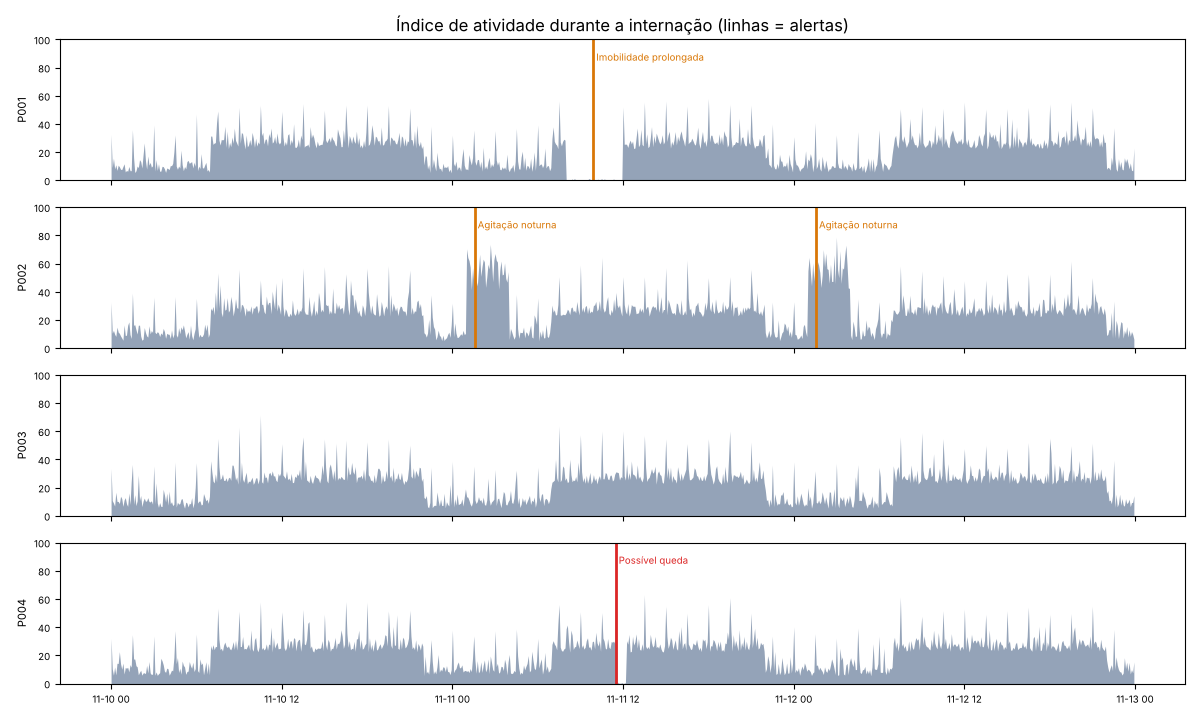

In [8]:
from hospital_monitor.anomaly.movement import MovementAnomalyDetector
from hospital_monitor.report import plot_movement
mov = pd.read_csv(files["movement"], parse_dates=["timestamp"])
mscored, malerts = MovementAnomalyDetector(cfg["movement"]).detect(mov)
for a in malerts:
    print(a.short(), "|", a.description)
display(Image(plot_movement(mscored, malerts, Path("outputs/figuras/movimentacao.png"))))

## 5. Áudio das consultas
Fluxo: **Azure Speech to Text** (transcrição pt-BR com tempo por palavra) → **Azure Text Analytics** (sentimento, entidades e *Text Analytics for Health*) → termos críticos; em paralelo, biomarcadores vocais extraídos do sinal.

### Consulta P003

Transcrição (transcricao_referencia): Bom dia doutora. Estou me sentindo bem melhor hoje. Dormi bem a noite toda, consegui caminhar no corredor pela manhã e estou me alimentando normalmente. A dor na perna diminuiu bastante.
Sentimento: positive | termos críticos: []


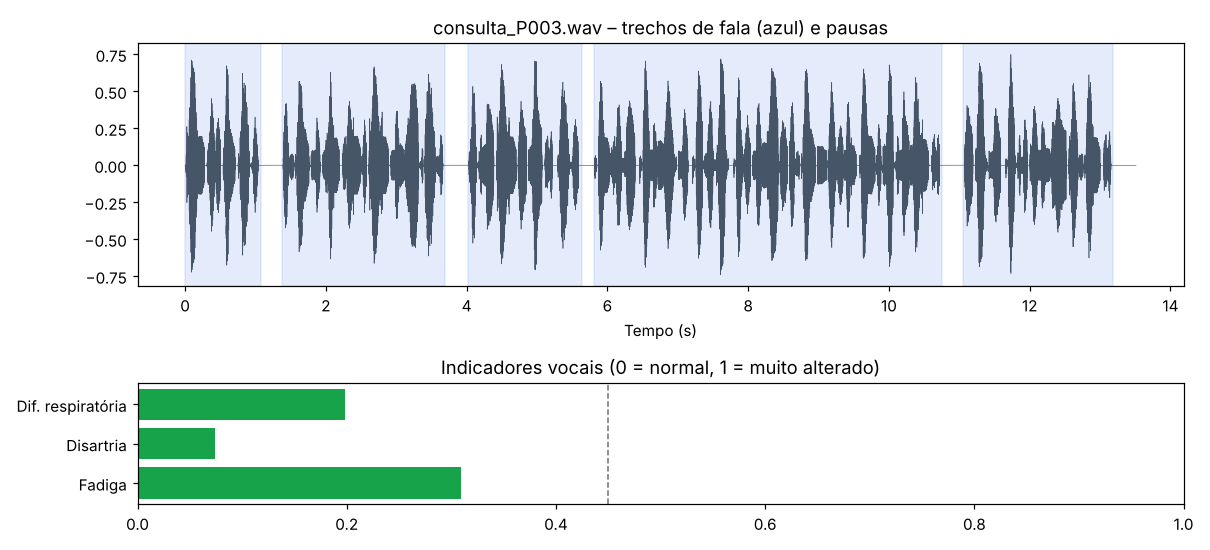

### Consulta P001

Transcrição (transcricao_referencia): Doutora, eu estou muito cansada. Desde ontem sinto falta de ar quando falo, e uma fraqueza no corpo todo. Tive febre e calafrios a noite. Estou com tontura quando levanto e não tenho vontade de comer.
Sentimento: negative | termos críticos: ['cansada', 'falta de ar', 'fraqueza', 'febre', 'calafrio', 'tontura', 'nao tenho vontade de comer']


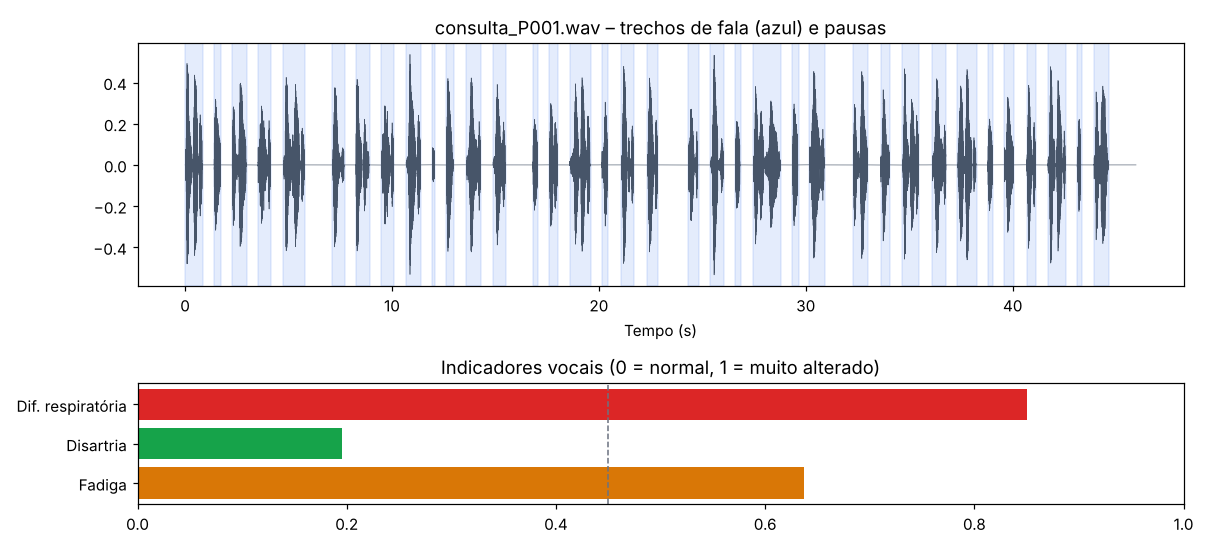

In [9]:
from hospital_monitor.audio.analyzer import AudioAnalyzer
from IPython.display import Audio
aa = AudioAnalyzer(cfg)
reports = {}
for pid in ["P003", "P001"]:
    wav = f"data/samples/consulta_{pid}.wav"
    display(Markdown(f"### Consulta {pid}"))
    display(Audio(wav))
    rep = aa.analyze(wav, pid, "outputs/audio")
    reports[pid] = rep
    print(f"Transcrição ({rep.transcription_provider}):", rep.transcript)
    print("Sentimento:", rep.sentiment.get("label"), "| termos críticos:",
          [t["term"] for t in rep.critical_terms if not t["negated"]])
    display(Image(f"outputs/audio/audio_consulta_{pid}.png"))

In [10]:
cols = ["articulation_rate", "pause_ratio", "pauses_per_min", "mean_phrase_s", "long_pauses", "f0_std_st"]
tab = pd.DataFrame({pid: {**{c: r.features[c] for c in cols},
                          **{k: v["score"] for k, v in r.indicators.items() if k != "componentes"}}
                    for pid, r in reports.items()})
tab

,P003,P001
articulation_rate,4.8841,3.1570
pause_ratio,0.0837,0.5104
pauses_per_min,13.6529,47.0430
mean_phrase_s,2.4160,0.6071
long_pauses,0.0000,4.0000
f0_std_st,1.3525,1.7106
fadiga,0.3090,0.6370
disartria,0.0740,0.1950
dificuldade_respiratoria,0.1980,0.8500


## 6. Vídeo
### 6.1 Sessão de fisioterapia (agachamento)
Keypoints no formato JSON do OpenPose, 8 repetições; as repetições 5 a 8 possuem desvios conhecidos.

,index,min_knee,max_trunk,max_asymmetry,issues
0,1,88.201306,30.839653,4.821656,[]
1,2,86.925322,32.907021,5.363741,[]
2,3,90.981439,28.342399,6.461636,[]
3,4,87.282208,33.695033,4.553064,[]
4,5,112.743537,26.693858,6.942600,[amplitude insuficiente (joelho mínimo 113° > ...
5,6,90.496507,62.170181,4.686005,[inclinação excessiva do tronco (62°)]
6,7,101.926244,34.663460,33.668468,[amplitude insuficiente (joelho mínimo 102° > ...
7,8,114.842115,50.300168,4.785366,[amplitude insuficiente (joelho mínimo 115° > ...


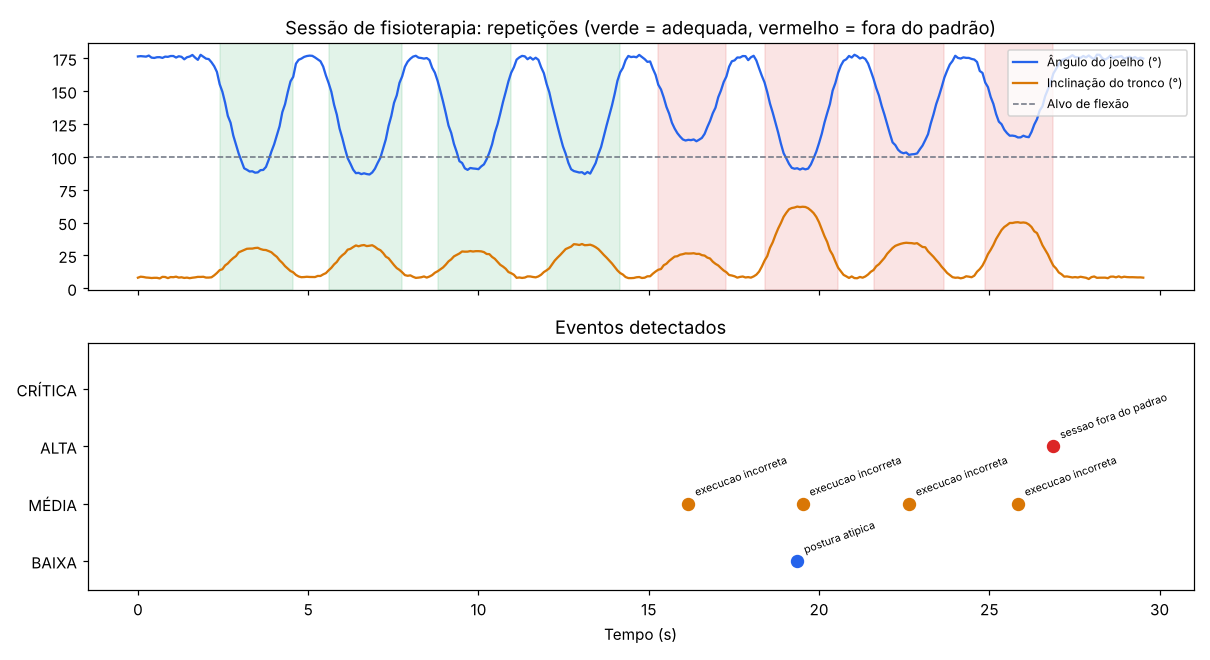

In [11]:
from datetime import datetime
from hospital_monitor.video.analyzer import VideoAnalyzer, events_to_alerts
from hospital_monitor.video.pose import OpenPoseJsonEstimator

va = VideoAnalyzer(cfg["video"], pose_estimator=OpenPoseJsonEstimator("data/samples/fisioterapia_openpose_json"))
rep_f = va.analyze("data/samples/fisioterapia_simulada.mp4", "P001", "fisioterapia", "outputs/video",
                   start_time=datetime(2026, 11, 11, 10, 0))
display(pd.DataFrame(rep_f.repetitions)[["index", "min_knee", "max_trunk", "max_asymmetry", "issues"]])
display(Image(rep_f.outputs["plot"]))

### 6.2 Queda no quarto (YOLOv8-pose + rastreamento)

4.6s | CRITICA | Possível queda da pessoa #1: quadril desceu 34% da altura corporal em <1 s e terminou em posição horizontal.


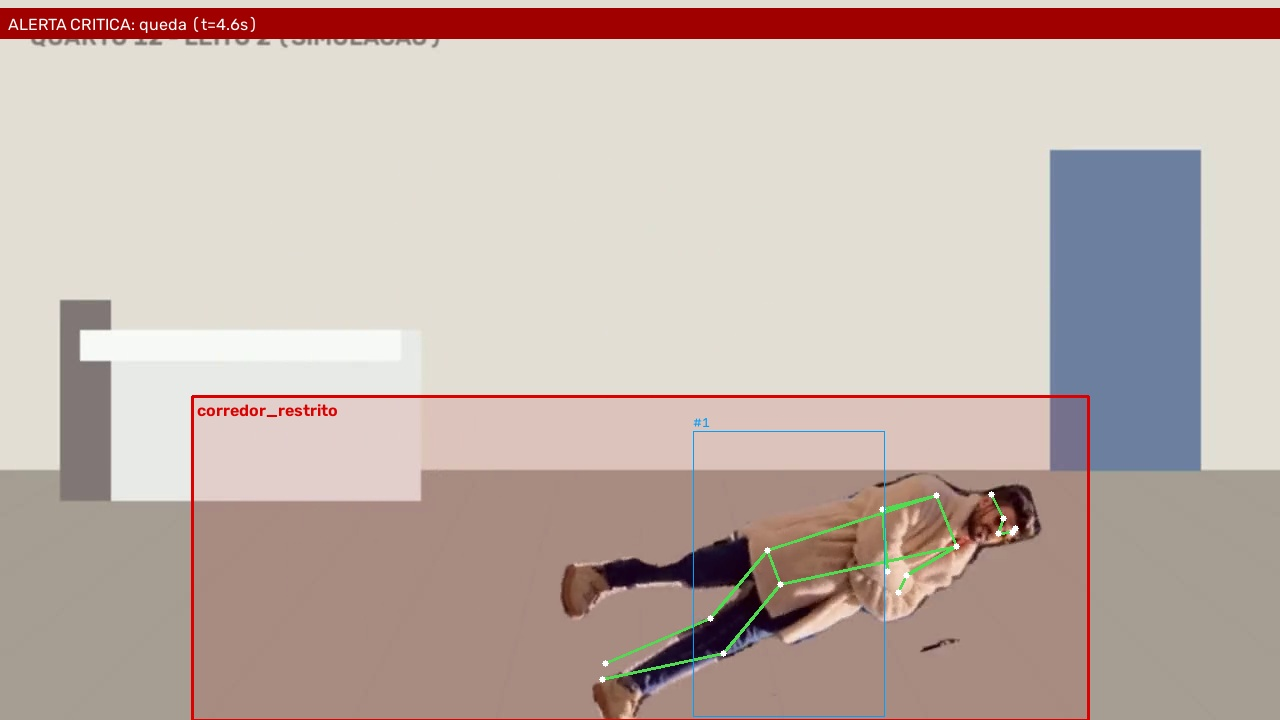

In [12]:
va_yolo = VideoAnalyzer(cfg["video"])
rep_q = va_yolo.analyze("data/samples/queda_simulada.mp4", "P004", "monitoramento", "outputs/video",
                        start_time=datetime(2026, 11, 11, 11, 29, 55))
for e in rep_q.events:
    print(f"{e.time_s:.1f}s | {e.severity.name} | {e.description}")
    display(Image(e.snapshot, width=720))

In [13]:
display(Markdown(open("outputs/video/fisioterapia_simulada/relatorio_video.md", encoding="utf-8").read()
                 .replace("![Linha do tempo](linha_do_tempo.png)", "")))

# Relatório automático de vídeo – fisioterapia_simulada.mp4

- Paciente: **P001** | Modo: **fisioterapia**
- Duração: 29.6 s | FPS: 25 | Frames analisados: 370
- Pessoas rastreadas: 1
- Objetos detectados (YOLOv8): nenhum

## Desvios e eventos detectados

| Tempo | Severidade | Tipo | Descrição |
|---|---|---|---|
| 16.2 s (10:00:16) | MEDIA | execucao_incorreta | Repetição 5 de agachamento: amplitude insuficiente (joelho mínimo 113° > alvo 100°). |
| 19.4 s (10:00:19) | BAIXA | postura_atipica | Padrão postural atípico por 0.6 s (Isolation Forest sobre ângulos articulares). |
| 19.5 s (10:00:19) | MEDIA | execucao_incorreta | Repetição 6 de agachamento: inclinação excessiva do tronco (62°). |
| 22.6 s (10:00:22) | MEDIA | execucao_incorreta | Repetição 7 de agachamento: amplitude insuficiente (joelho mínimo 102° > alvo 100°); assimetria entre joelhos (34°). |
| 25.8 s (10:00:25) | MEDIA | execucao_incorreta | Repetição 8 de agachamento: amplitude insuficiente (joelho mínimo 115° > alvo 100°); inclinação excessiva do tronco (50°). |
| 26.9 s (10:00:26) | ALTA | sessao_fora_do_padrao | 4 de 8 repetições fora do padrão esperado. Sugere fadiga, dor ou necessidade de ajustar o exercício. |

## Repetições do exercício

| # | Início (s) | Joelho mín. (°) | Tronco máx. (°) | Assimetria (°) | Problemas |
|---|---|---|---|---|---|
| 1 | 2.4 | 88 | 31 | 5 | adequada |
| 2 | 5.6 | 87 | 33 | 5 | adequada |
| 3 | 8.8 | 91 | 28 | 6 | adequada |
| 4 | 12.0 | 87 | 34 | 5 | adequada |
| 5 | 15.3 | 113 | 27 | 7 | amplitude insuficiente (joelho mínimo 113° > alvo 100°) |
| 6 | 18.4 | 90 | 62 | 5 | inclinação excessiva do tronco (62°) |
| 7 | 21.6 | 102 | 35 | 34 | amplitude insuficiente (joelho mínimo 102° > alvo 100°); assimetria entre joelhos (34°) |
| 8 | 24.9 | 115 | 50 | 5 | amplitude insuficiente (joelho mínimo 115° > alvo 100°); inclinação excessiva do tronco (50°) |




## 7. Fusão multimodal e alertas para a equipe médica

In [14]:
from hospital_monitor.pipeline import run_demo
res = run_demo(cfg, console=False)
alerts = pd.DataFrame([a.to_dict() for a in res["alerts"]])
display(alerts[["timestamp", "patient_id", "severity", "source", "title"]])
pd.DataFrame(res["summary"]["risco_por_paciente"]).T

,timestamp,patient_id,severity,source,title
0,2026-11-10T16:00:00,P004,ALTA,prescription,Alteração brusca de dose: Insulina regular
1,2026-11-10T16:00:00,P004,MEDIA,prescription,Alterações frequentes: Insulina regular
2,2026-11-10T18:00:00,P002,ALTA,prescription,Interação medicamentosa: Varfarina + AAS
3,2026-11-10T20:00:00,P004,ALTA,prescription,Alteração brusca de dose: Insulina regular
4,2026-11-10T20:00:00,P004,MEDIA,prescription,Alterações frequentes: Insulina regular
5,2026-11-10T20:01:00,P002,CRITICA,vitals,Anomalia em sinais vitais
6,2026-11-10T20:01:00,P002,CRITICA,fusion,Risco multimodal elevado
7,2026-11-10T22:00:00,P002,ALTA,prescription,Interação medicamentosa: Varfarina + Enoxaparina
8,2026-11-11T01:35:00,P002,MEDIA,movement,Agitação noturna
9,2026-11-11T02:00:00,P001,CRITICA,prescription,Dose acima do máximo diário: Morfina


,peak_risk,modalities,peak_time,severity,n_alerts
P004,1.0,"{'video': 0.9, 'movement': 0.7, 'vitals': 0.55}",2026-11-11 12:02:00,CRITICA,7
P002,1.0,"{'vitals': 1.0, 'prescription': 0.7, 'movement...",2026-11-11 01:35:00,CRITICA,5
P001,1.0,"{'vitals': 0.9500000000000001, 'audio': 0.85, ...",2026-11-11 10:00:26.880000,CRITICA,10
P003,0.25,{'prescription': 0.25},2026-11-11 03:00:00,BAIXA,1


,timestamp,patient_id,severity,description
6,2026-11-10T20:01:00,P002,CRITICA,Risco combinado 1.00 a partir de 2 fontes conc...
14,2026-11-11T07:30:00,P001,CRITICA,Risco combinado 1.00 a partir de 2 fontes conc...
23,2026-11-11T11:30:00,P004,CRITICA,Risco combinado 1.00 a partir de 2 fontes conc...


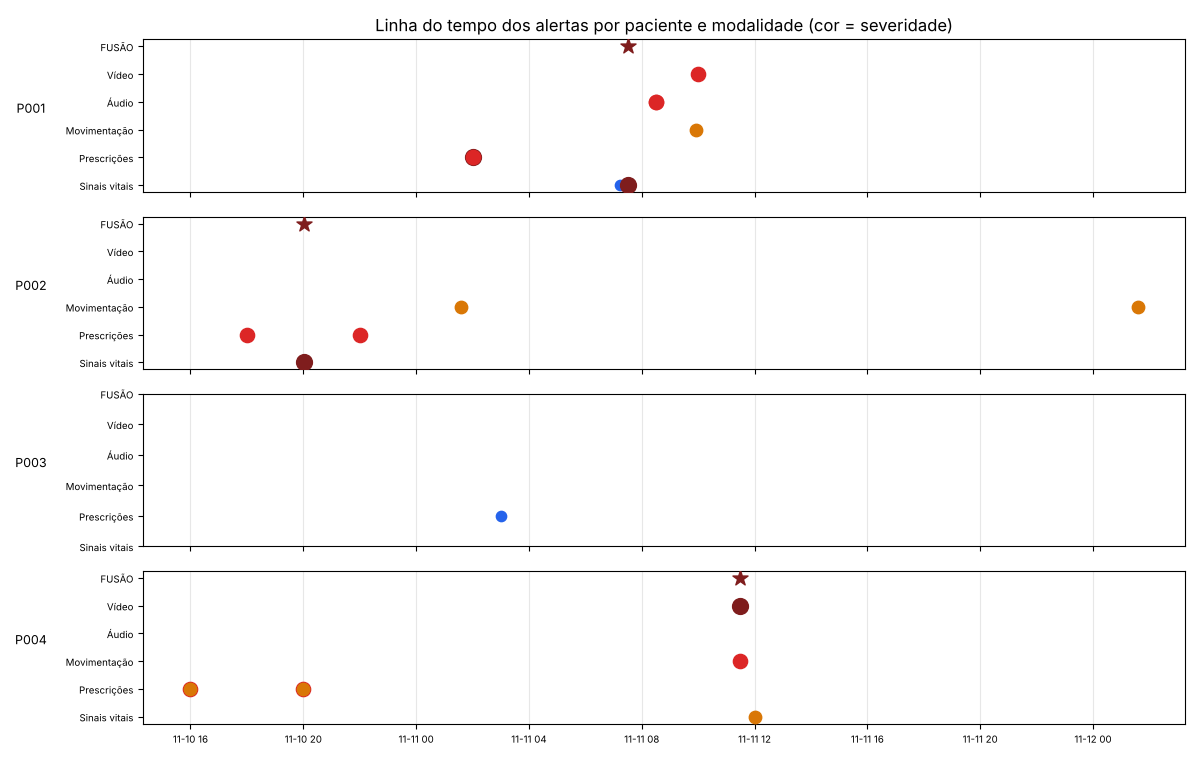

Painel da equipe médica: /home/user/pos-tech-challenge-fase-4/outputs/painel_equipe_medica.html


In [15]:
display(alerts[alerts.source == "fusion"][["timestamp", "patient_id", "severity", "description"]])
display(Image("outputs/figuras/alertas_timeline.png"))
print("Painel da equipe médica:", res["summary"]["painel"])

## 8. Conclusão
- 3 de 3 episódios de sinais vitais detectados, sem falsos positivos, e detecção antecipada em relação ao NEWS2 isolado;
- erros de prescrição, interações e padrões anormais de movimentação identificados;
- voz com sinais de fadiga e dispneia diferenciada da consulta normal, com termos críticos extraídos da transcrição;
- desvios na execução do exercício e queda detectados no vídeo;
- alertas de risco multimodal emitidos apenas quando fontes independentes concordam.